# Prepare and inspect the shared questions

This phase follows exploration and precedes feature creation. **No API calls, model loads or generated features.** All six decision models will reuse the same saved task definitions and questions. Only the wording appropriate to each dataset's actual task is generated.

## 1. Validate source meanings and freeze the 18 task schemas

Definitions are hard-coded in `config/dataset_semantics.yaml`, with source URLs and unresolved facts explicitly recorded. Raw target values, feature names and CSVs remain unchanged. All 80 official text fields have descriptions; undocumented details remain identified as such.

,dataset,meaning,task,raw_target,target_meaning,classes,text_columns,review_notes
0,Fake Job Postings,Employment Scam Aegean job advertisements,binary_classification,fraudulent,whether the job advertisement is fraudulent,2,3,0
1,Jigsaw Toxicity,Jigsaw online comment toxicity,binary_classification,Is Toxic,whether the comment is toxic,2,1,0
2,Kickstarter,Kickstarter project funding,binary_classification,Funding Status,whether the project achieved its funding goal,2,3,0
3,Data Scientist Salary,Indian data-science job salary bands,multiclass_classification,salary,advertised annual salary band in lakh Indian r...,6,5,1
4,Michelin Guide,MICHELIN Guide restaurant distinctions,multiclass_classification,Award,MICHELIN culinary distinction,5,6,0
5,Product Sentiment,MachineHack product-review sentiment,multiclass_classification,Sentiment,sentiment expressed in the product review,4,1,1
6,US Accidents,US road-accident traffic impact,multiclass_classification,Severity,accident severity in terms of impact on traffic,4,6,1
7,Wine Review,Wine Enthusiast wine-variety reviews,multiclass_classification,variety,wine variety or blend category,30,2,0
8,Women's Clothing,Women's e-commerce clothing reviews,multiclass_classification,Rating,customer rating of the clothing item,5,2,0
9,Baby Products,Babies R Us product prices,regression,price,listed baby-product price,0,4,1


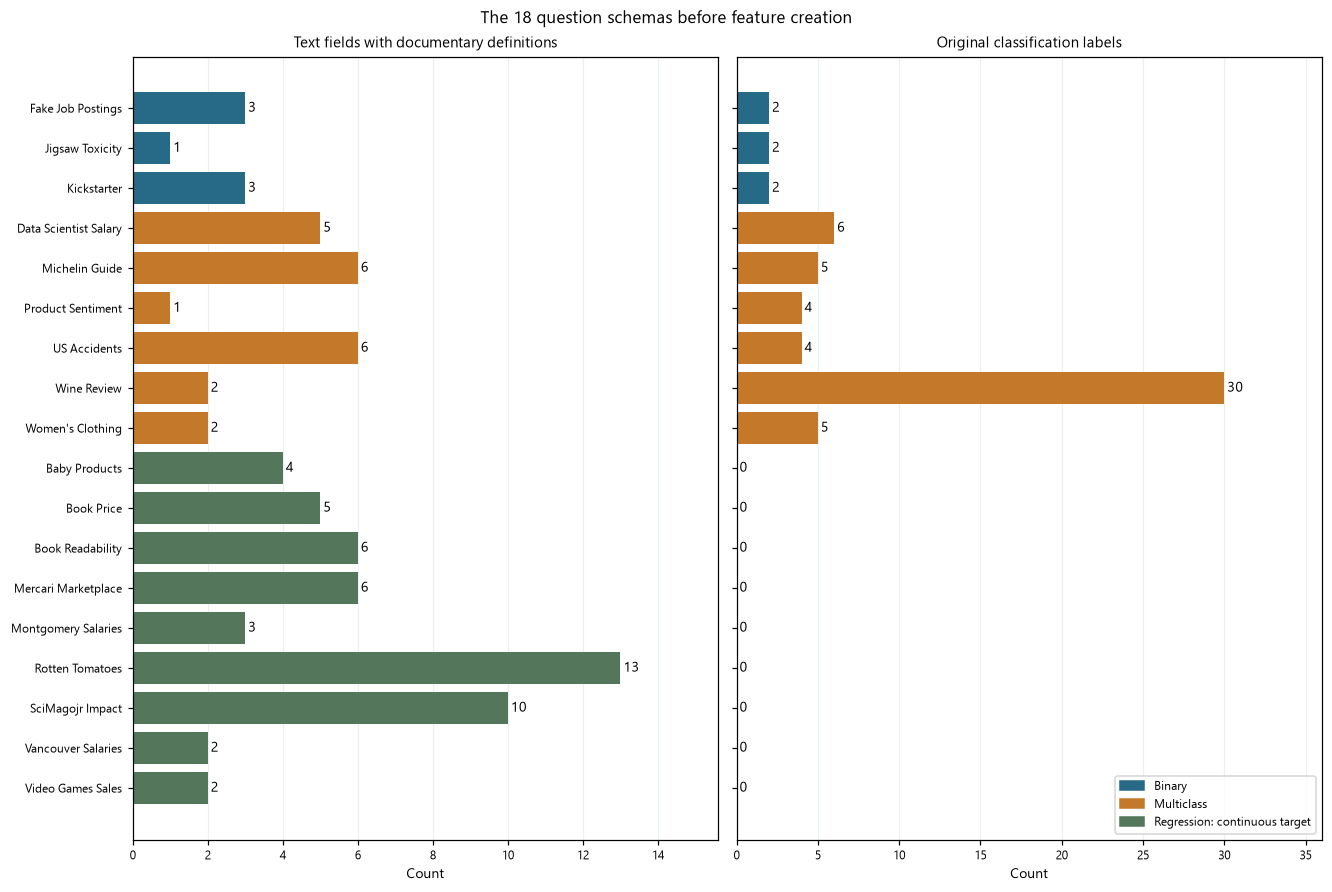

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import json
import matplotlib.pyplot as plt
from src.utils.config import load_config, save_resolved_config
from src.utils.notebook_display import display_local, display_json
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.jev.preparation import prepare_questions, preparation_tables
from src.jev.provider import semantic_question
from src.visualize import figures, style
from src.visualize.questions import question_schema_figure
style.apply()
NOTEBOOK = "question_preparation/01_prepare_questions"
begin_report()
report_section("1. Source-backed task schemas")
save = figures.FigureSaver(NOTEBOOK)
cfg = load_config("question_preparation")
save_resolved_config(cfg, NOTEBOOK)
bank, bank_file, exports = prepare_questions(cfg)
tables = preparation_tables(bank)
display_local(tables["datasets"].drop(columns=["dataset_id", "question"]))
fig, name, caption = question_schema_figure(tables["datasets"])
save(fig, name, caption=caption)
display_local(fig)
plt.close(fig)

## 2. Exact class translations and text-column meanings

`c000`, `c001`, … are stable API option IDs, not new class labels. Their order follows the original typed vocabulary. For example, salary bands retain their original strings; descriptions add lakh INR/year. Accident classes remain traffic-impact levels, without invented injury categories. Product sentiment retains `Cannot Say` separately from `No Sentiment`.

In [2]:
report_section("2. Raw-to-readable class and column mappings")
display_local(tables["classes"])
display_local(tables["text_fields"])

,dataset,option_id,raw_value,meaning
0,Fake Job Postings,c000,0,legitimate job advertisement
1,Fake Job Postings,c001,1,fraudulent job advertisement
2,Jigsaw Toxicity,c000,False,non-toxic comment
3,Jigsaw Toxicity,c001,True,toxic comment
4,Kickstarter,c000,Failed,funding goal not achieved
5,Kickstarter,c001,Successful,funding goal achieved
6,Data Scientist Salary,c000,0-3,annual salary band 0-3 lakh Indian rupees
7,Data Scientist Salary,c001,10-15,annual salary band 10-15 lakh Indian rupees
8,Data Scientist Salary,c002,15-25,annual salary band 15-25 lakh Indian rupees
9,Data Scientist Salary,c003,25-50,annual salary band 25-50 lakh Indian rupees


,dataset,raw_column,meaning
0,Fake Job Postings,title,advertised job title
1,Fake Job Postings,salary_range,"advertised salary range, as written"
2,Fake Job Postings,description,job advertisement description
3,Jigsaw Toxicity,comment_text,comment text
4,Kickstarter,name,project title
...,...,...,...
75,SciMagojr Impact,Areas,subject areas
76,Vancouver Salaries,name,employee name
77,Vancouver Salaries,title,employee job title
78,Video Games Sales,Name,video-game title


## 3. Every question and the exact provider-neutral answer definition

Binary: one positive-class probability. Multiclass: all class probabilities. Regression: the shared nine-level rubric and its expected direction. These JSON objects show exactly the meanings passed to each provider's Noul/Choice/Score interface. Notebook 02 shows complete row-text and provider-specific call previews.

The `documented` variant uses the new source-backed descriptions. `accepted` preserves the earlier wording, and `proposed_direct` preserves the earlier shorter candidate. Saving a new question version does not enable paid extraction.

In [3]:
report_section("3. All 18 documented questions and answer definitions")
for dataset_id, entry in bank["datasets"].items():
    variant = entry["variants"]["documented"]
    display_json(entry["task"]["dataset"], {"dataset_id": dataset_id, "raw_target": entry["task"]["target"], "documentary_context": variant["documentary_definition"], "question": variant["question"], "provider_neutral_question": semantic_question(variant["question"]), "class_mapping": entry["semantics"]["classes"]})

## 4. Evidence and facts still needing care

The Book Price target keeps the misleading raw name `Price in USD`; the earlier benchmark documents a log transformation. The prompt describes log-price rather than asserting a dollar amount. Baby-product currency/company-field details, the `British Words` field, and the movie-rating scale remain unspecified. No target values or label-derived statistics are used to resolve these meanings.

In [4]:
report_section("4. Sources and explicit uncertainties")
display_local(tables["sources"])
display_local(tables["review_notes"])

,dataset,url,evidence,sha256
0,Fake Job Postings,https://github.com/alanarazi7/MulTaBench/blob/...,"Pinned MulTaBench dataset annotation: task, ra...",d626ea93acc82c50b8b8ceb15125ee768ed39310f0c97a...
1,Fake Job Postings,https://www.kaggle.com/datasets/shivamb/real-o...,Original dataset card: fake versus legitimate ...,NaN
2,Jigsaw Toxicity,https://github.com/alanarazi7/MulTaBench/blob/...,"Pinned MulTaBench dataset annotation: task, ra...",ff9c3d2a6e91b0b181933199c230b68304c0d86fc71960...
3,Jigsaw Toxicity,https://github.com/sxjscience/automl_multimoda...,The benchmark preparation defines target as th...,NaN
4,Kickstarter,https://github.com/alanarazi7/MulTaBench/blob/...,"Pinned MulTaBench dataset annotation: task, ra...",55d5acc8af8965f6a98e1ede508157f8957461756fcdec...
5,Data Scientist Salary,https://github.com/alanarazi7/MulTaBench/blob/...,"Pinned MulTaBench dataset annotation: task, ra...",799b325d4e9c983fbc249bd355cba0685ee291f00204be...
6,Data Scientist Salary,https://www.kaggle.com/datasets/ankitkalauni/p...,Dataset mirror reproduces the MachineHack desc...,NaN
7,Data Scientist Salary,https://github.com/chetanambi/Predict-The-Data...,Original competition participant reproduces th...,NaN
8,Michelin Guide,https://github.com/alanarazi7/MulTaBench/blob/...,"Pinned MulTaBench dataset annotation: task, ra...",4e2baa49138375e52c3fbd01c640ade819b38492de4260...
9,Michelin Guide,https://guide.michelin.com/us/en/article/featu...,"MICHELIN defines its stars, Bib Gourmand and s...",NaN


,dataset,review_note
0,Data Scientist Salary,The original MachineHack page is unavailable. ...
1,Product Sentiment,Cannot Say and No Sentiment remain separate so...
2,US Accidents,Do not invent delay cutoffs or fatality meanin...
3,Baby Products,The source annotation does not establish the c...
4,Book Price,Raw column name Price in USD is misleading: up...
5,Book Readability,Do not conflate the chosen formula target with...
6,Rotten Tomatoes,The legacy source file is named rotten_tomatoe...


## 5. Saved questions and selecting one decision model's features

Reusable inputs: `data/decision_inputs/questions/<bank_id>/<dataset_id>.json`, with a complete bank JSON beside that directory. Review copies: `output_JEVPFN/question_preparation/questions/<bank_id>/<dataset_id>.json`. These contain metadata and questions, **not row text or target values**. Changed wording creates a different hash and leaves previous versions intact.

Later, `data/jev_cache/<dataset_id>.sqlite3` holds that dataset's responses and feature tables for every decision model. Select provider + model/version + question bank + question variant, then per-column, joint or both. Ambiguous selection is rejected. These examples only display a selection specification; there are no paid feature files yet.

In [5]:
report_section("5. Permanent inputs, review exports and feature selection")
display_json("Saved files", {"bank_id": bank["bank_id"], "canonical_bank": str(bank_file), "per_dataset_review_exports": [str(p) for p in exports], "api_enabled": cfg["jev"]["enabled"]})
display_json("Example future feature selection", {"provider": "jev", "model": "jev-1.13.0", "version": "1.13.0", "question_bank_id": bank["bank_id"], "question_variant": "documented", "representations": ["per_column", "joint"], "feature_view": "main"})
record({"inventory": "src.jev.features.feature_inventory(path)", "load_selected": "src.evaluation.features.load_feature_selection(path, selector)", "assemble": "src.evaluation.features.assemble_feature_set(dataset, blocks, 'non_text_plus_both', selector=selector)", "other_provider_response_decoders": "Not implemented; preview and cache identities only."}, "Implementation boundary")

## Complete preparation report

Every displayed definition, question, source and unresolved issue is included below and in `output_JEVPFN/All Results.md`.

In [6]:
finish_report(NOTEBOOK, f"Prepared {len(bank['datasets'])} datasets and {len(tables['text_fields'])} text-field definitions. Bank: {bank['bank_id']}.\nAll six models share task wording; responses remain model-specific. No API calls or feature extraction.\n" + save.summary())

question_preparation/01_prepare_questions

1. Source-backed task schemas

              dataset                                                meaning                      task                         raw_target                                      target_meaning  classes  text_columns  review_notes
    Fake Job Postings              Employment Scam Aegean job advertisements     binary_classification                         fraudulent         whether the job advertisement is fraudulent        2             3             0
      Jigsaw Toxicity                         Jigsaw online comment toxicity     binary_classification                           Is Toxic                        whether the comment is toxic        2             1             0
          Kickstarter                            Kickstarter project funding     binary_classification                     Funding Status       whether the project achieved its funding goal        2             3             0
Data Scientist Sal